# Thendokhae Eulandah Netshikhophani_ST10513894

# EDA

In [9]:
!sudo apt update
!apt-get install openjdk-8-jdk-headless -qq > /dev/null
#Check this site for the latest download link https://www.apache.org/dyn/closer.lua/spark/spark-3.2.1/spark-3.2.1-bin-hadoop3.2.tgz
!wget -q https://dlcdn.apache.org/spark/spark-3.2.1/spark-3.2.1-bin-hadoop3.2.tgz
!tar xf spark-3.2.1-bin-hadoop3.2.tgz
!pip install -q findspark
!pip install pyspark
!pip install py4j

import os
import sys
# os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-8-openjdk-amd64"
# os.environ["SPARK_HOME"] = "/content/spark-3.2.1-bin-hadoop3.2"


import findspark
findspark.init()
findspark.find()

import pyspark

from pyspark.sql import DataFrame, SparkSession
from typing import List
import pyspark.sql.types as T
import pyspark.sql.functions as F

spark= SparkSession \
       .builder \
       .appName("Our First Spark Example") \
       .getOrCreate()

spark

Get:1 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:2 https://cli.github.com/packages stable InRelease [3,917 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:4 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Hit:5 http://archive.ubuntu.com/ubuntu noble InRelease
Get:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:7 http://security.ubuntu.com/ubuntu noble-security/universe amd64 Packages [1,552 kB]
Get:8 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:9 http://security.ubuntu.com/ubuntu noble-security/main amd64 Packages [1,422 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,116 kB]
Get:11 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,132 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:13 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Pac

# Conducting the analysis using Python and PySpark

# 1. Importing libraries

In [10]:
!pip install pyspark tensorflow pillow scikit-learn seaborn matplotlib pandas

# General libraries

In [11]:
import os
import re
import hashlib
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from io import BytesIO

# PySpark libraries

In [12]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import (
    col, count, when, split, explode,
    array_contains, lit
)


# Machine learning and evaluation

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# TensorFlow and Keras

In [14]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


# Set random seeds

In [15]:
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully.")

All libraries imported successfully.


# 2. Creating the PySpark session

In [16]:
spark = SparkSession.builder \
    .appName("Book Cover Image Recognition CNN") \
    .master("local[*]") \
    .getOrCreate()

print("Spark session created successfully.")
print("Spark version:", spark.version)

Spark session created successfully.
Spark version: 4.0.5


# 3. Loading dataset using PySpark

In [17]:
df_spark = spark.read.csv(
    "book_data.csv",
    header=True,
    inferSchema=True,
    multiLine=True,
    escape='"'
)

# Display sample records

In [18]:
df_spark.show(5, truncate=50)

+--------------------------------------------------+--------------------------------------------------+----------------------------------+-----------+-----------+----------+-----------+-----------------+-----------------+-----------------------------------------+--------------------------------------------------+--------------------------------------------------+
|                                      book_authors|                                         book_desc|                      book_edition|book_format|  book_isbn|book_pages|book_rating|book_rating_count|book_review_count|                               book_title|                                            genres|                                         image_url|
+--------------------------------------------------+--------------------------------------------------+----------------------------------+-----------+-----------+----------+-----------+-----------------+-----------------+-----------------------------------------+-----

# Display schema

In [19]:
df_spark.printSchema()

root
 |-- book_authors: string (nullable = true)
 |-- book_desc: string (nullable = true)
 |-- book_edition: string (nullable = true)
 |-- book_format: string (nullable = true)
 |-- book_isbn: string (nullable = true)
 |-- book_pages: string (nullable = true)
 |-- book_rating: string (nullable = true)
 |-- book_rating_count: string (nullable = true)
 |-- book_review_count: string (nullable = true)
 |-- book_title: string (nullable = true)
 |-- genres: string (nullable = true)
 |-- image_url: string (nullable = true)



# Display dimensions

In [20]:
print("Total records:", df_spark.count())
print("Total columns:", len(df_spark.columns))

Total records: 70518
Total columns: 12


# 4. Examining the missing values using PySpark

In [21]:
missing_values = df_spark.select([
    count(
        when(
            col(c).isNull() | ((col(c) == "") if dtype == "string" else lit(False)),
            c
        )
    ).alias(c)
    for c, dtype in df_spark.dtypes
])

missing_values.show(truncate=False)

+------------+---------+------------+-----------+---------+----------+-----------+-----------------+-----------------+----------+------+---------+
|book_authors|book_desc|book_edition|book_format|book_isbn|book_pages|book_rating|book_rating_count|book_review_count|book_title|genres|image_url|
+------------+---------+------------+-----------+---------+----------+-----------+-----------------+-----------------+----------+------+---------+
|0           |1846     |63216       |2396       |18561    |3618      |3          |1                |1                |3         |5171  |971      |
+------------+---------+------------+-----------+---------+----------+-----------+-----------------+-----------------+----------+------+---------+



# 5.Data cleaning

# Record original dataset size

In [22]:
original_count = df_spark.count()


# Remove records without book titles

In [23]:
df_spark = df_spark.filter(
    col("book_title").isNotNull()
)

# Remove records without authors

In [24]:
df_spark = df_spark.filter(
    col("book_authors").isNotNull()
)


# Remove records without image URLs

In [25]:
df_spark = df_spark.filter(
    col("image_url").isNotNull() &
    (col("image_url") != "")
)


# Remove records without genre information

In [26]:
df_spark = df_spark.filter(
    col("genres").isNotNull() &
    (col("genres") != "")
)


# Remove duplicate book title and author combinations

In [27]:
df_spark = df_spark.dropDuplicates(
    ["book_title", "book_authors"]
)


# Remove duplicate image URLs

In [28]:
df_spark = df_spark.dropDuplicates(
    ["image_url"]
)

# Display cleaning results

In [29]:
cleaned_count = df_spark.count()

print("Original records:", original_count)
print("Cleaned records:", cleaned_count)
print("Records removed:", original_count - cleaned_count)

Original records: 70518
Cleaned records: 42446
Records removed: 28072


# 6. Examining the distribution of book genres

# Split multiple genres into individual records

In [30]:
genre_df = df_spark.withColumn(
    "genre",
    explode(split(col("genres"), r"\|"))
)

# Count each genre

In [31]:
genre_counts = genre_df.groupBy(
    "genre"
).count().orderBy(
    col("count").desc()
)

genre_counts.show(20, truncate=False)

+-------------------+-----+
|genre              |count|
+-------------------+-----+
|Fiction            |21352|
|Fantasy            |19817|
|Romance            |15649|
|Young Adult        |9459 |
|Historical         |8901 |
|Paranormal         |6889 |
|Nonfiction         |6502 |
|Mystery            |6452 |
|Science Fiction    |5441 |
|Historical Fiction |5295 |
|Classics           |5228 |
|Contemporary       |5074 |
|Cultural           |4437 |
|Childrens          |4398 |
|Literature         |3829 |
|Sequential Art     |3058 |
|Thriller           |2924 |
|Religion           |2626 |
|European Literature|2580 |
|History            |2324 |
+-------------------+-----+
only showing top 20 rows


# Convert genre summary to Pandas

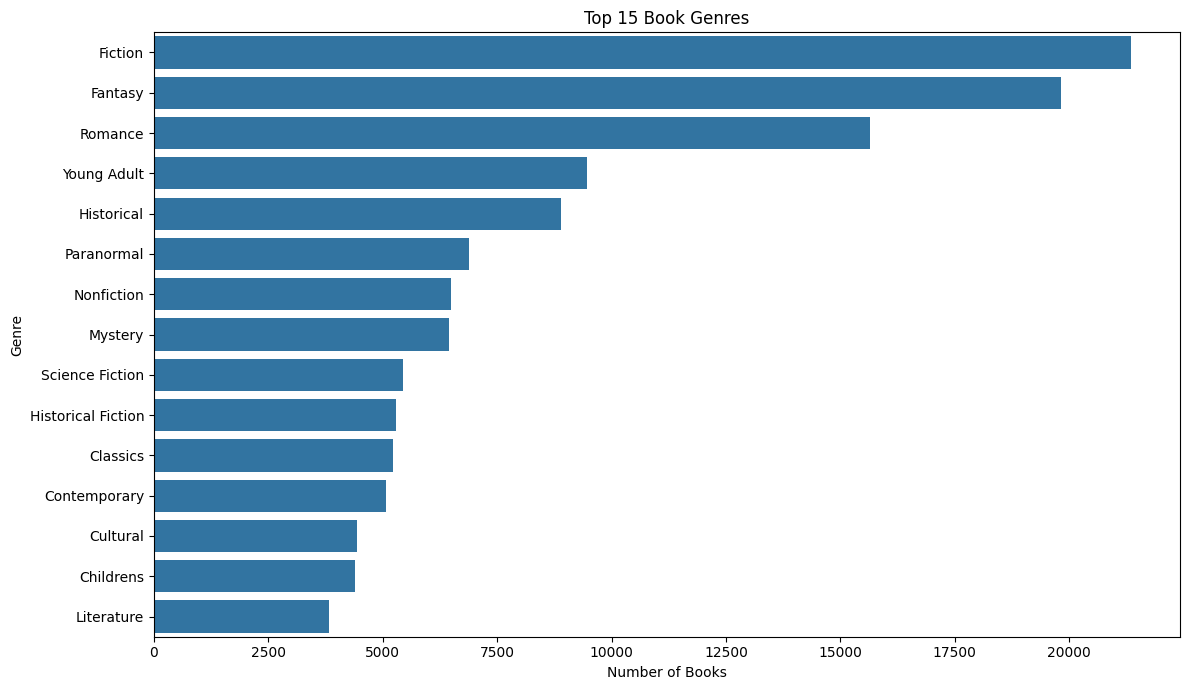

In [32]:
genre_pdf = genre_counts.limit(15).toPandas()

plt.figure(figsize=(12, 7))

sns.barplot(
    data=genre_pdf,
    x="count",
    y="genre"
)

plt.title("Top 15 Book Genres")
plt.xlabel("Number of Books")
plt.ylabel("Genre")

plt.tight_layout()
plt.show()

# 7 Create five image-classification categories

# Split genre strings into arrays

In [33]:
df_spark = df_spark.withColumn(
    "genre_array",
    split(col("genres"), r"\|")
)

# Assign one class using a consistent priority

In [34]:
df_spark = df_spark.withColumn(
    "label",
    when(
        array_contains(col("genre_array"), "Young Adult"),
        lit("Young Adult")
    ).when(
        array_contains(col("genre_array"), "Fantasy"),
        lit("Fantasy")
    ).when(
        array_contains(col("genre_array"), "Romance"),
        lit("Romance")
    ).when(
        array_contains(col("genre_array"), "Historical"),
        lit("Historical")
    ).when(
        array_contains(col("genre_array"), "Fiction"),
        lit("Fiction")
    )
)


# Retain only selected categories

In [35]:
df_spark = df_spark.filter(
    col("label").isNotNull()
)

# Display class distribution

In [36]:
df_spark.groupBy(
    "label"
).count().orderBy(
    col("count").desc()
).show()

+-----------+-----+
|      label|count|
+-----------+-----+
|Young Adult| 8775|
|    Fiction| 8233|
|    Fantasy| 7076|
|    Romance| 5451|
| Historical| 3045|
+-----------+-----+



# 8. Balance the image dataset

# Balancing classes using PySpark

In [37]:
from pyspark.sql.window import Window
from pyspark.sql.functions import row_number

# Set maximum number of images per category

In [38]:
MAX_IMAGES = 1000


# Randomly select images within each class

In [39]:
window = Window.partitionBy(
    "label"
).orderBy(
    col("image_url")
)

# Assign row numbers

In [40]:
df_spark = df_spark.withColumn(
    "row_number",
    row_number().over(window)
)


# Keep maximum number of records per class

In [41]:
balanced_spark = df_spark.filter(
    col("row_number") <= MAX_IMAGES
).drop(
    "row_number"
)

# Display balanced class distribution

In [42]:
balanced_spark.groupBy(
    "label"
).count().show()

print(
    "Total selected images:",
    balanced_spark.count()
)

+-----------+-----+
|      label|count|
+-----------+-----+
|    Fantasy| 1000|
|    Fiction| 1000|
| Historical| 1000|
|    Romance| 1000|
|Young Adult| 1000|
+-----------+-----+

Total selected images: 5000


# 9. Examine sample image URLs

# Convert selected metadata to Pandas

In [43]:
image_metadata = balanced_spark.select(
    "book_title",
    "book_authors",
    "genres",
    "label",
    "image_url"
).toPandas()

print(image_metadata.head())

print("\nImages per category:")
print(image_metadata["label"].value_counts())

                         book_title              book_authors  \
0                   Hades' Daughter             Sara Douglass   
1                      Song of Kali               Dan Simmons   
2          The Dreamland Chronicles          Wm. Mark Simmons   
3           The Great Book of Amber             Roger Zelazny   
4  The Giraffe and the Pelly and Me  Roald Dahl|Quentin Blake   

                                              genres    label  \
0  Fantasy|Science Fiction Fantasy|Fantasy|Epic F...  Fantasy   
1     Horror|Fantasy|Fiction|Thriller|Cultural|India  Fantasy   
2                            Fantasy|Science Fiction  Fantasy   
3  Fantasy|Fiction|Science Fiction|Science Fictio...  Fantasy   
4                          Childrens|Fiction|Fantasy  Fantasy   

                                           image_url  
0                  https://images.gr-asseof thirteen  
1  https://images.gr-assets.com/books/1165368440l...  
2  https://images.gr-assets.com/books/1165427780l... 

# 4. Download and prepare the book-cover images

# 4.1 Downloading images from the supplied URLs

# Create image storage directory

In [44]:
IMAGE_DIR = "book_cover_images"

os.makedirs(IMAGE_DIR, exist_ok=True)


# Store successful downloads

In [45]:
downloaded_records = []


# Download images

In [46]:
for index, row in image_metadata.iterrows():

    image_url = row["image_url"]
    label = row["label"]



 # Download image

In [47]:
import requests
from PIL import Image
from io import BytesIO
import os

# Combine the loop and download logic to avoid IndentationError
for index, row in image_metadata.iterrows():
    image_url = row["image_url"]
    label = row["label"]
    book_title = row["book_title"]
    book_authors = row["book_authors"]

    # Generate a unique local filename using MD5 hash of the URL
    img_hash = hashlib.md5(image_url.encode('utf-8')).hexdigest()
    img_filename = f"{img_hash}.jpg"
    img_path = os.path.join(IMAGE_DIR, img_filename)

    try:
        # Fetch image
        response = requests.get(
            image_url,
            timeout=15,
            headers={
                "User-Agent": "Mozilla/5.0"
            }
        )
        response.raise_for_status()

        # Open and verify it is a valid image
        img = Image.open(BytesIO(response.content))
        img.convert("RGB").save(img_path, "JPEG")

        # Track successfully downloaded records
        downloaded_records.append({
            "book_title": book_title,
            "book_authors": book_authors,
            "label": label,
            "image_path": img_path
        })

    except Exception as e:
        # Silently pass or print error for troubleshooting broken URLs
        continue

print(f"Successfully downloaded {len(downloaded_records)} images.")

Successfully downloaded 4997 images.


# Open image and convert to RGB

In [48]:
image = Image.open(
            BytesIO(response.content)
        ).convert("RGB")

 # Resize image

In [49]:
 image = image.resize((128, 128))

# Create category directory

In [50]:
category_dir = os.path.join(
    IMAGE_DIR,
    label.replace(" ", "_")
)

os.makedirs(
    category_dir,
    exist_ok=True
)

 # Create unique filename

In [51]:
filename = hashlib.md5(
    image_url.encode()
).hexdigest() + ".jpg"

filepath = os.path.join(
    category_dir,
    filename
)

# Save image

In [52]:
try:
    image.save(filepath, format="JPEG")

    downloaded_records.append({
        "filepath": filepath,
        "label": label,
        "book_title": row["book_title"]
    })

except Exception as error:
    print(
        "Image download failed:",
        index,
        str(error)[:100]
    )

# Create successful download DataFrame

In [53]:
downloaded_df = pd.DataFrame(
    downloaded_records
)


# Save image metadata

In [54]:
downloaded_df.to_csv(
    "downloaded_book_images.csv",
    index=False
)

print("\nDownload completed.")

print(
    "Successfully downloaded images:",
    len(downloaded_df)
)

print("\nImages per category:")
print(downloaded_df["label"].value_counts())


Download completed.
Successfully downloaded images: 4998

Images per category:
label
Historical     1000
Young Adult    1000
Romance        1000
Fantasy         999
Fiction         999
Name: count, dtype: int64


# 4.2 Check the downloaded images

# Display sample images

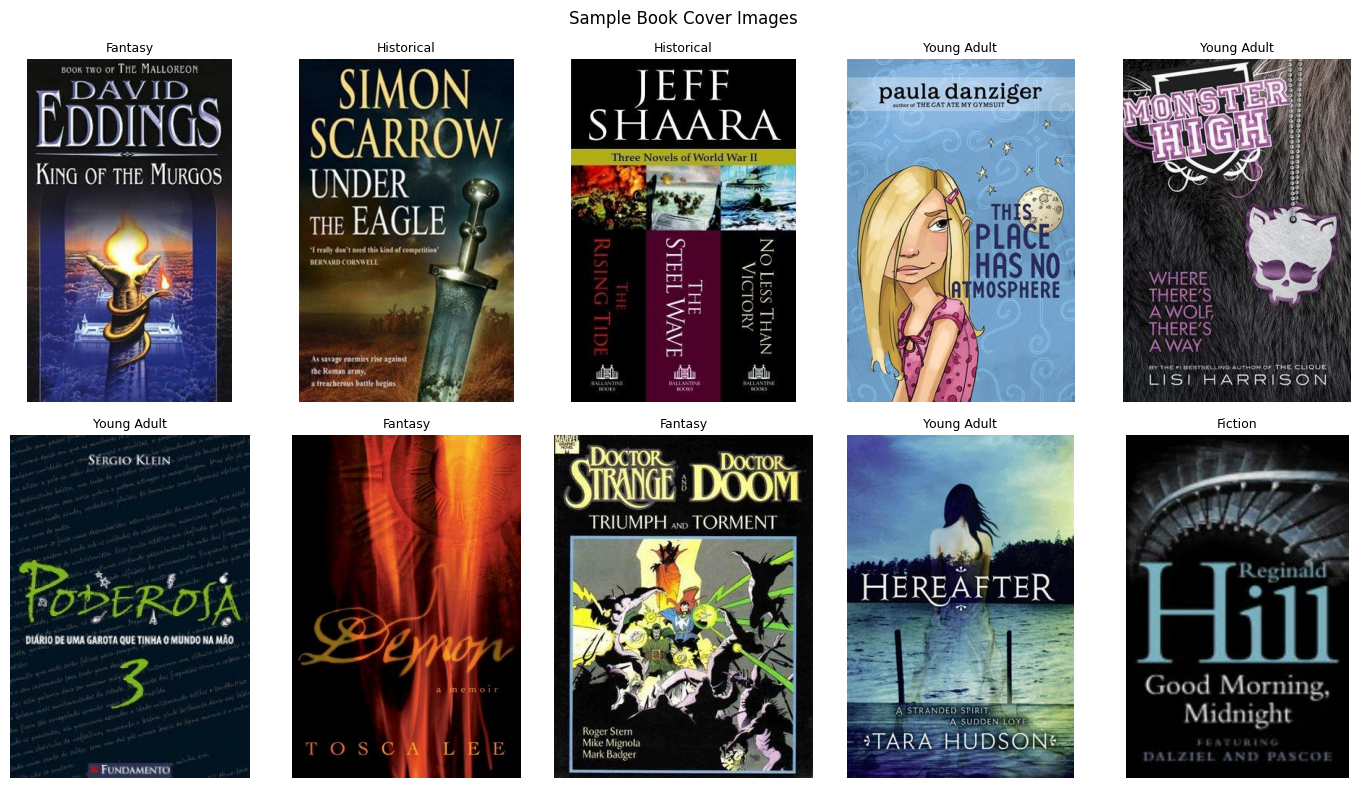

In [55]:
sample_images = downloaded_df.sample(
    min(10, len(downloaded_df)),
    random_state=42
)

plt.figure(figsize=(14, 8))

plot_index = 1
for i, (_, row) in enumerate(
    sample_images.iterrows()
):
    # Handle both potential column names 'image_path' and 'filepath'
    path_key = "image_path" if "image_path" in row and pd.notna(row["image_path"]) else "filepath"
    img_path = row.get(path_key, None)

    if not img_path or pd.isna(img_path):
        continue

    try:
        image = Image.open(img_path)

        plt.subplot(2, 5, plot_index)
        plt.imshow(image)
        plt.title(
            row.get("label", "Unknown"),
            fontsize=9
        )
        plt.axis(
            "off"
        )
        plot_index += 1
        if plot_index > 10:
            break
    except Exception as e:
        print(f"Could not load image at {img_path}: {e}")

plt.suptitle("Sample Book Cover Images")
plt.tight_layout()
plt.show()

# 4.3 Check the Number of Images per Class

# Image class distribution

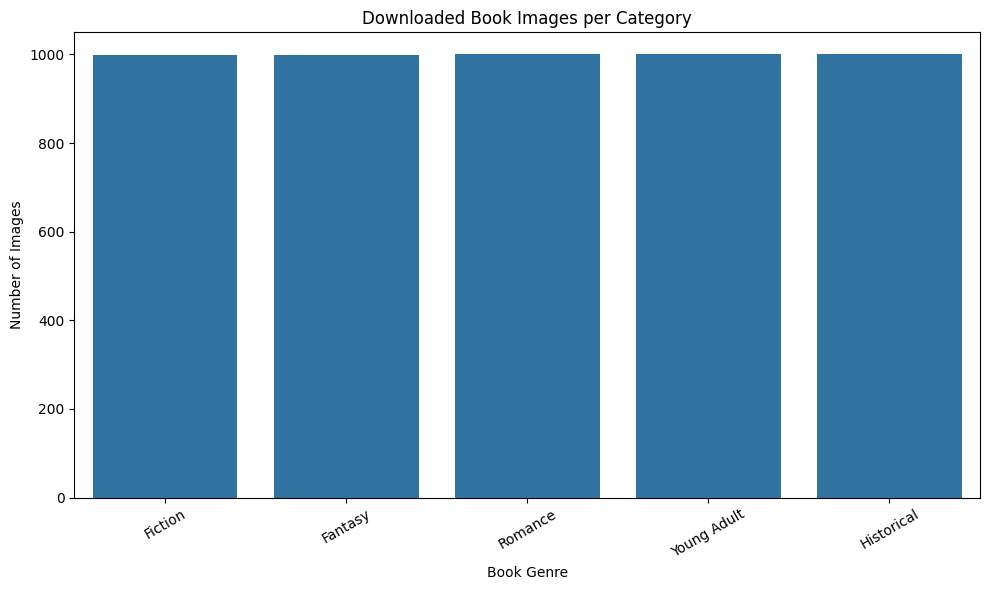

In [56]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=downloaded_df,
    x="label",
    order=[
        "Fiction",
        "Fantasy",
        "Romance",
        "Young Adult",
        "Historical"
    ]
)

plt.title("Downloaded Book Images per Category")
plt.xlabel("Book Genre")
plt.ylabel("Number of Images")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

# 5. Preparing the image data for CNN training

# 5.1 Encode genre labels

# Define genre categories

In [57]:
class_names = [
    "Fiction",
    "Fantasy",
    "Historical",
    "Romance",
    "Young Adult"
]

# Create numerical label mapping

In [58]:
label_mapping = {
    name: index
    for index, name in enumerate(class_names)
}


# Encode labels

In [59]:
downloaded_df["encoded_label"] = (
    downloaded_df["label"].map(label_mapping)
)

print("Label mapping:")
print(label_mapping)

print("\nEncoded dataset:")
print(downloaded_df.head())

Label mapping:
{'Fiction': 0, 'Fantasy': 1, 'Historical': 2, 'Romance': 3, 'Young Adult': 4}

Encoded dataset:
                                     book_title  \
0                                  Song of Kali   
1                      The Dreamland Chronicles   
2                       The Great Book of Amber   
3              The Giraffe and the Pelly and Me   
4  Unfinished Tales of Númenor and Middle-Earth   

                         book_authors    label  \
0                         Dan Simmons  Fantasy   
1                    Wm. Mark Simmons  Fantasy   
2                       Roger Zelazny  Fantasy   
3            Roald Dahl|Quentin Blake  Fantasy   
4  J.R.R. Tolkien|Christopher Tolkien  Fantasy   

                                          image_path filepath  encoded_label  
0  book_cover_images/c9a5203d2d9c89e40716d74f5aae...      NaN              1  
1  book_cover_images/72b748b15e31a1336590d80533d7...      NaN              1  
2  book_cover_images/4fb84eceb81d7ac5f5722aa

# 5.2 Split the dataset into training, validation and testing sets

# Extract image paths and labels

In [60]:
image_paths = downloaded_df["filepath"].values

labels = downloaded_df["encoded_label"].values


# First split: 70% training, 30% remaining

In [61]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: 15% validation, 15% testing

In [62]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Training images: 3498
Validation images: 750
Testing images: 750


# 5.3 Create TensorFlow image datasets

# Define image dimensions

In [63]:
IMG_SIZE = 128

# Define batch size

In [64]:
BATCH_SIZE = 32


# Function to load and preprocess images

In [65]:
def load_image(filepath, label):

    # Read image file
    image = tf.io.read_file(filepath)

    # Decode JPEG
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalise pixels to 0-1
    image = image / 255.0

    return image, label



# Create TensorFlow dataset

In [66]:
def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:

        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


# Create training dataset

In [67]:
# Extract correct image paths using 'image_path' instead of the empty 'filepath'
image_paths = downloaded_df["image_path"].values
labels = downloaded_df["encoded_label"].values

# Re-split dataset with corrected paths
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Splits successfully recreated with valid image paths:")
print(f" - Training images: {len(X_train)}")
print(f" - Validation images: {len(X_val)}")
print(f" - Testing images: {len(X_test)}")

# Create training dataset successfully
train_ds = create_dataset(
    X_train,
    y_train,
    training=True
)
print("\nTraining dataset created successfully!")

Splits successfully recreated with valid image paths:
 - Training images: 3498
 - Validation images: 750
 - Testing images: 750

Training dataset created successfully!


In [68]:
# Clean the downloaded dataframe to ensure no NaN values exist in 'image_path'
clean_downloaded_df = downloaded_df.dropna(subset=["image_path"])

# Extract clean paths and labels
image_paths = clean_downloaded_df["image_path"].values
labels = clean_downloaded_df["encoded_label"].values

# Re-split dataset with clean, non-NaN string paths
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Re-create all three datasets with clean data
train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val, training=False)
test_ds = create_dataset(X_test, y_test, training=False)

print("All datasets (Train, Val, Test) created successfully without NaN errors!")
print(f"Training batches: {len(list(train_ds.take(1)))}")

All datasets (Train, Val, Test) created successfully without NaN errors!
Training batches: 1


In [69]:
# Define CNN Architecture using Keras 3 standard Input layer
model = keras.Sequential([
    # Dedicated Input Layer to prevent Keras warnings
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # Convolutional Block 1
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolutional Block 2
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Convolutional Block 3
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Dense Layers
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation='softmax')
])

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

# Train the model
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,519,237 (24.87 MB)

 Trainable params: 6,518,277 (24.87 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.2308 - loss: 2.2712 - val_accuracy: 0.2000 - val_loss: 2.9484
Epoch 2/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.2434 - loss: 2.0038 - val_accuracy: 0.2107 - val_loss: 1.8921
Epoch 3/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.2943 - loss: 1.7659 - val_accuracy: 0.2213 - val_loss: 2.0677
Epoch 4/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.3003 - loss: 1.7126 - val_accuracy: 0.2160 - val_loss: 1.7584
Epoch 5/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.3223 - loss: 1.6382 - val_accuracy: 0.2960 - val_loss: 1.6200
Epoch 6/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 202s 2s/step - accuracy: 0.3514 - loss: 1.5785 - val_accuracy: 0.2640 - val_loss: 1.5990
Epoch 7/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.3675 - loss: 1.5217 - val_accuracy: 0.2827 - val_loss: 1.5863
Epoch 8/10
110/110 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.3941 - loss: 1.4420 - val_accu

# Create validation dataset

In [70]:
def create_dataset(paths, labels, training=False):
    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset

In [71]:
# The datasets (train_ds, val_ds, test_ds) have already been defined and processed successfully in cell bc5a06d4.
print("Datasets are ready for training. Using val_ds and test_ds generated from cell bc5a06d4.")

Datasets are ready for training. Using val_ds and test_ds generated from cell bc5a06d4.


# 5.4 Verify the image dimensions

# Display one batch of images

In [72]:
import tensorflow as tf

# Verify the image dimensions directly from the training dataset
try:
    for images, labels_batch in train_ds.take(1):
        print("Image batch shape:", images.shape)
        print("Label batch shape:", labels_batch.shape)
        print("Minimum pixel value:", tf.reduce_min(images).numpy())
        print("Maximum pixel value:", tf.reduce_max(images).numpy())
except NameError as e:
    print("Error:", e)
    print("Please run the earlier cells in your notebook (such as cell 'bc5a06d4') to load the data and define 'train_ds' first.")

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# Training the CNN mode

# 6.2 Building initial CNN model

In [74]:
model = keras.Sequential([

    # Input layer
    layers.Input(
        shape=(128, 128, 3)
    ),

    # First convolutional layer
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Second convolutional layer
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Third convolutional layer
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Flatten feature maps
    layers.Flatten(),

    # Fully connected layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # Dropout
    layers.Dropout(0.3),

    # Output layer
    layers.Dense(
        5,
        activation="softmax"
    )
])

# Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

# 6.3 Compiling CNN

In [75]:
model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN model compiled successfully.")

CNN model compiled successfully.


# 6.4 Training initial CNN model

In [76]:
history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    verbose=1
)

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 132s 1s/step - accuracy: 0.2022 - loss: 1.6284 - val_accuracy: 0.2147 - val_loss: 1.6019
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 129s 1s/step - accuracy: 0.2156 - loss: 1.6055 - val_accuracy: 0.2320 - val_loss: 1.6040
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.2371 - loss: 1.5991 - val_accuracy: 0.2293 - val_loss: 1.6018
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 127s 1s/step - accuracy: 0.2737 - loss: 1.5730 - val_accuracy: 0.2827 - val_loss: 1.6073
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.3214 - loss: 1.4976 - val_accuracy: 0.2787 - val_loss: 1.6256
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 126s 1s/step - accuracy: 0.4058 - loss: 1.3697 - val_accuracy: 0.2720 - val_loss: 1.6908
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.5182 - loss: 1.1621 - val_accuracy: 0.2613 - val_loss: 1.8988
Epoch 8/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 128s 1s/step - accuracy: 0.6185 - loss: 0.9280 - val_accu

# 6.5 Visualising training accuracy

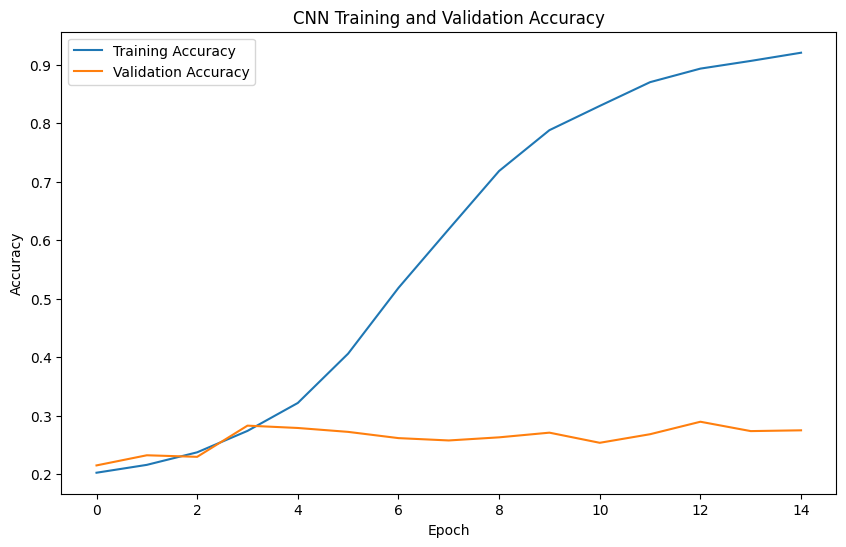

In [77]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

# 6.6 Visualising training loss

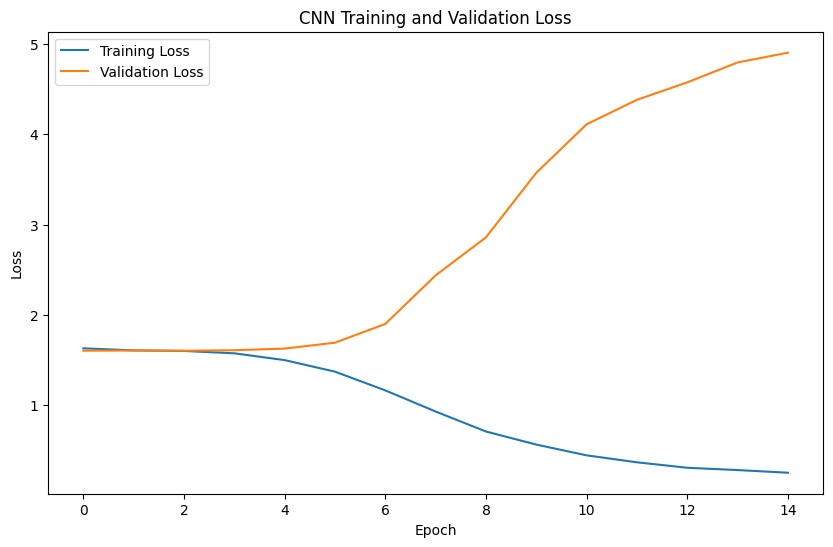

In [78]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()

# 7. Evaluating the CNN model

# 7.1 Evaluating CNN on testing data

In [79]:
test_loss, test_accuracy = model.evaluate(
    test_ds
)

print("Initial CNN Test Results")

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 287ms/step - accuracy: 0.2453 - loss: 4.5803
Initial CNN Test Results
Test Loss: 4.580293655395508
Test Accuracy: 0.24533332884311676


# 7.2 Generating predictions

In [80]:
y_prob = model.predict(test_ds)

# Convert probabilities into predicted classes
y_pred = np.argmax(
    y_prob,
    axis=1
)

# Actual labels
y_actual = y_test

print("Predictions generated successfully.")

24/24 ━━━━━━━━━━━━━━━━━━━━ 10s 416ms/step
Predictions generated successfully.


# 7.3 Calculating evaluation metrics

In [81]:
print("Accuracy:",
      accuracy_score(y_actual, y_pred))

print("Precision:",
      precision_score(
          y_actual,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_actual,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("F1-score:",
      f1_score(
          y_actual,
          y_pred,
          average="weighted",
          zero_division=0
      ))

print("\nDetailed Classification Report:")

print(
    classification_report(
        y_actual,
        y_pred,
        labels=list(range(5)),
        target_names=class_names,
        zero_division=0
    )
)

Accuracy: 0.24533333333333332
Precision: 0.24480179277929168
Recall: 0.24533333333333332
F1-score: 0.24366281494671918

Detailed Classification Report:
              precision    recall  f1-score   support

     Fiction       0.23      0.22      0.22       150
     Fantasy       0.23      0.20      0.22       150
  Historical       0.29      0.26      0.27       150
     Romance       0.22      0.21      0.22       150
 Young Adult       0.26      0.33      0.29       150

    accuracy                           0.25       750
   macro avg       0.24      0.25      0.24       750
weighted avg       0.24      0.25      0.24       750



# 7.4 Generating the confusion matrix

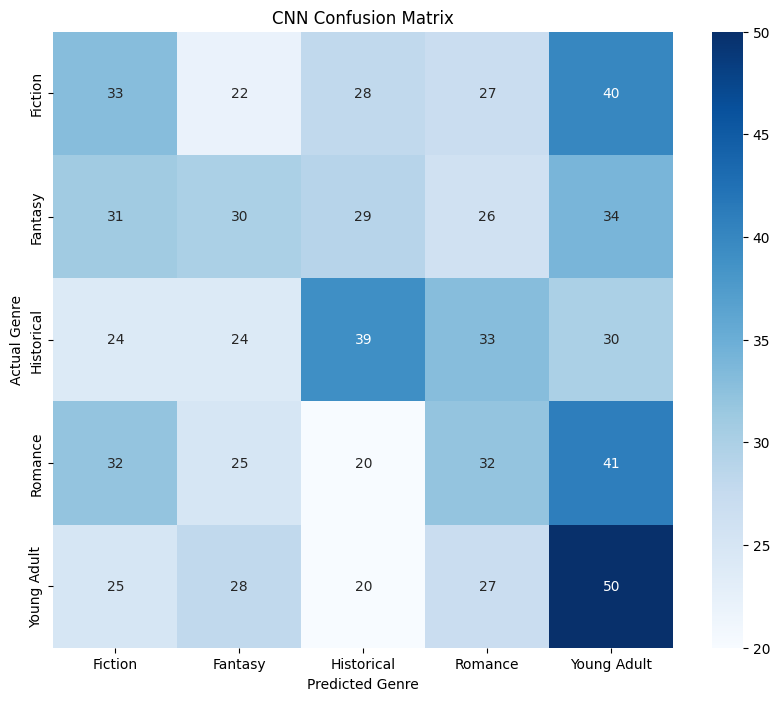

In [82]:
# Calculate confusion matrix
cm = confusion_matrix(
    y_actual,
    y_pred,
    labels=list(range(5))
)

# Plot confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")

plt.show()

# 7.5 Displaying actual and predicted images

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step


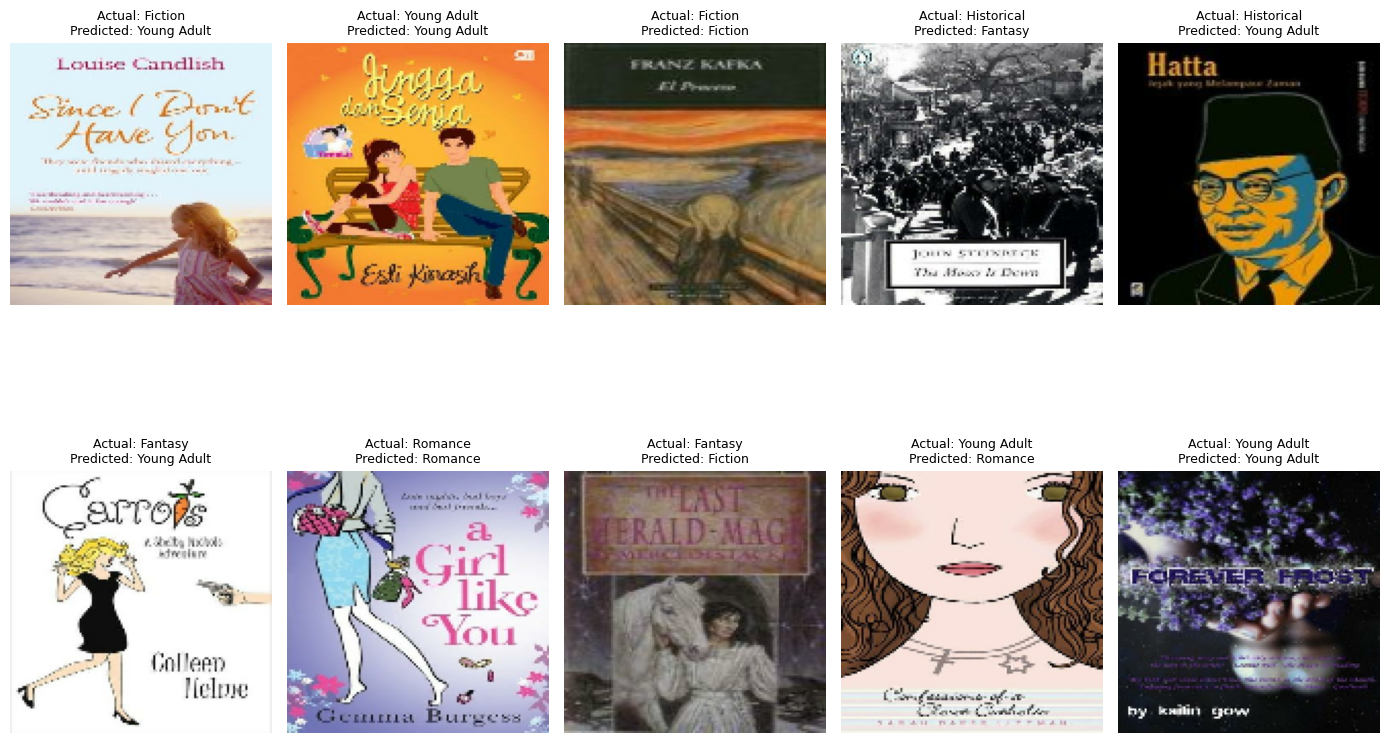

In [83]:
# Display sample predictions
plt.figure(figsize=(14, 10))

for images, labels_batch in test_ds.take(1):

    predictions = model.predict(images)

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    for i in range(min(10, len(images))):

        plt.subplot(2, 5, i + 1)

        plt.imshow(images[i].numpy())

        actual = class_names[
            int(labels_batch[i].numpy())
        ]

        predicted = class_names[
            predicted_labels[i]
        ]

        plt.title(
            f"Actual: {actual}\nPredicted: {predicted}",
            fontsize=9
        )

        plt.axis("off")

plt.tight_layout()
plt.show()

# 8. Improving and retraining the CNN model

# 8.1 Data augmentation

In [84]:
# Create data augmentation layer
data_augmentation = keras.Sequential([

    layers.RandomFlip("horizontal"),

    layers.RandomRotation(0.10),

    layers.RandomZoom(0.10),

    layers.RandomContrast(0.10)

])

print("Data augmentation created.")

Data augmentation created.


# 8.2 Build improved CNN architecture

In [85]:
# Create improved CNN
improved_model = keras.Sequential([

    layers.Input(
        shape=(128, 128, 3)
    ),

    # Apply data augmentation during training
    data_augmentation,

    # First convolutional block
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Second convolutional block
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Third convolutional block
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Fourth convolutional block
    layers.Conv2D(
        256,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    # Flatten
    layers.Flatten(),

    # Dense layer
    layers.Dense(
        128,
        activation="relu"
    ),

    # Increased dropout
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(
        5,
        activation="softmax"
    )
])

# Display architecture
improved_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,486,341 (9.48 MB)

 Trainable params: 2,486,341 (9.48 MB)

 Non-trainable params: 0 (0.00 B)

# 8.3 Compile improved model

In [86]:
improved_model.compile(

    optimizer=keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("Improved CNN compiled.")

Improved CNN compiled.


# 8.4 Configuring callbacks

In [87]:
# Stop training when validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(

    monitor="val_loss",

    patience=5,

    restore_best_weights=True
)

# Reduce learning rate when validation loss plateaus
reduce_lr = keras.callbacks.ReduceLROnPlateau(

    monitor="val_loss",

    factor=0.5,

    patience=3,

    min_lr=0.00001
)

print("Callbacks configured successfully.")

Callbacks configured successfully.


# 8.5 Retrain improved CNN

In [88]:
improved_history = improved_model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=25,

    callbacks=[
        early_stopping,
        reduce_lr
    ],

    verbose=1
)

Epoch 1/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 212s 2s/step - accuracy: 0.1967 - loss: 1.6129 - val_accuracy: 0.2000 - val_loss: 1.6088 - learning_rate: 5.0000e-04
Epoch 2/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 198s 2s/step - accuracy: 0.2170 - loss: 1.6088 - val_accuracy: 0.2347 - val_loss: 1.6039 - learning_rate: 5.0000e-04
Epoch 3/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 196s 2s/step - accuracy: 0.2251 - loss: 1.6063 - val_accuracy: 0.2187 - val_loss: 1.6020 - learning_rate: 5.0000e-04
Epoch 4/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.2259 - loss: 1.6036 - val_accuracy: 0.2467 - val_loss: 1.5963 - learning_rate: 5.0000e-04
Epoch 5/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 209s 2s/step - accuracy: 0.2325 - loss: 1.5986 - val_accuracy: 0.2320 - val_loss: 1.5862 - learning_rate: 5.0000e-04
Epoch 6/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 199s 2s/step - accuracy: 0.2376 - loss: 1.5970 - val_accuracy: 0.2413 - val_loss: 1.5959 - learning_rate: 5.0000e-04
Epoch 7/25
110/110 ━━━━━━━━━━━━━━━━━━━━ 207s 2s/step - acc

# 8.6 Evaluate improved model

In [89]:
improved_loss, improved_accuracy = (
    improved_model.evaluate(test_ds)
)

print("Improved CNN Test Results")

print("Test Loss:", improved_loss)

print("Test Accuracy:", improved_accuracy)

24/24 ━━━━━━━━━━━━━━━━━━━━ 14s 532ms/step - accuracy: 0.2760 - loss: 1.5743
Improved CNN Test Results
Test Loss: 1.5742872953414917
Test Accuracy: 0.2759999930858612


# 8.7 Compare initial and improved models

In [90]:
improved_probabilities = improved_model.predict(
    test_ds
)

improved_predictions = np.argmax(
    improved_probabilities,
    axis=1
)

# Calculate evaluation metrics
comparison = pd.DataFrame({

    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],

    "Initial CNN": [
        accuracy_score(y_actual, y_pred),

        precision_score(
            y_actual,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        recall_score(
            y_actual,
            y_pred,
            average="weighted",
            zero_division=0
        ),

        f1_score(
            y_actual,
            y_pred,
            average="weighted",
            zero_division=0
        )
    ],

    "Improved CNN": [
        accuracy_score(
            y_actual,
            improved_predictions
        ),

        precision_score(
            y_actual,
            improved_predictions,
            average="weighted",
            zero_division=0
        ),

        recall_score(
            y_actual,
            improved_predictions,
            average="weighted",
            zero_division=0
        ),

        f1_score(
            y_actual,
            improved_predictions,
            average="weighted",
            zero_division=0
        )
    ]

})

print(comparison.to_string(index=False))

24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 596ms/step
   Metric  Initial CNN  Improved CNN
 Accuracy     0.245333      0.276000
Precision     0.244802      0.274327
   Recall     0.245333      0.276000
 F1-score     0.243663      0.243933


# 8.8 Visualising model comparison

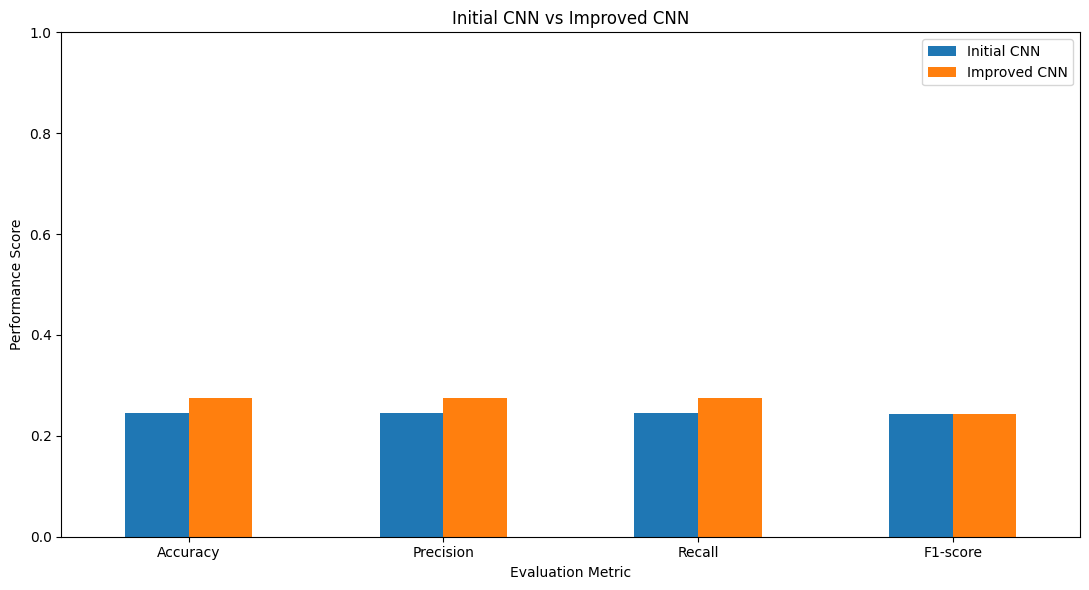

In [91]:
comparison_plot = comparison.set_index(
    "Metric"
)

comparison_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Initial CNN vs Improved CNN")
plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")

plt.xticks(rotation=0)

plt.ylim(0, 1)

plt.legend()

plt.tight_layout()
plt.show()

# The trained model

In [92]:
# Save improved CNN model
improved_model.save(
    "book_cover_cnn_model.keras"
)

# Save class labels
import json

with open(
    "class_names.json",
    "w"
) as file:

    json.dump(
        class_names,
        file
    )

print("CNN model saved successfully.")

CNN model saved successfully.
